## **Cell 1: Imports and config**

In [1]:
%load_ext autoreload
%autoreload 2

import sys, time, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PROJECT_ROOT / "data").exists(), f"Wrong project root: {PROJECT_ROOT}"
sys.path.insert(0, str(PROJECT_ROOT))

CATEGORY = "metal_nut"
REPORT_DIR = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR    = PROJECT_ROOT / "reports" / "figures"
MODEL_DIR  = PROJECT_ROOT / "models"
for d in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Experiment settings ----------
IMAGE_SIZE   = 256
BATCH_SIZE   = 8
POOL_KERNEL  = 3
SEED         = 42
PROJ_DIM     = 128
RATIOS       = [0.01, 0.05, 0.10, 0.25]

# ---------------- SWITCH ----------------
# Flip this between "baseline" and "concat", restart the kernel, re-run everything.
EMBED_MODE = "baseline"       # "baseline" | "concat"

if EMBED_MODE == "baseline":
    EMBED_DIM = 1024
    TAG       = "baseline1024"
    EMB_PATH  = MODEL_DIR / f"{CATEGORY}_train_emb_baseline_1024.pt"
elif EMBED_MODE == "concat":
    EMBED_DIM = 1536
    TAG       = "concat1536"
    EMB_PATH  = MODEL_DIR / f"{CATEGORY}_train_emb_concat_1536.pt"
else:
    raise ValueError(f"Unknown EMBED_MODE: {EMBED_MODE}")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device     : {device}")
print(f"EMBED_MODE : {EMBED_MODE}")
print(f"EMBED_DIM  : {EMBED_DIM}")
print(f"TAG        : {TAG}")
print(f"EMB_PATH   : {EMB_PATH}")
print(f"EMB exists : {EMB_PATH.exists()}")

Device     : cuda
EMBED_MODE : baseline
EMBED_DIM  : 1024
TAG        : baseline1024
EMB_PATH   : c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\models\metal_nut_train_emb_baseline_1024.pt
EMB exists : True


In [2]:
OVERWRITE = True

CORESET_CODE = r'''
import torch
import torch.nn.functional as F


@torch.inference_mode()
def greedy_coreset(features, n_select, proj_dim=128, seed=42, device="cuda"):
    """
    Greedy k-center coreset selection on L2-normalised features.

    Args:
        features : (N, D) float tensor on `device`
        n_select : number of patches to keep
        proj_dim : random projection dimension
        seed     : RNG seed

    Returns:
        LongTensor of selected indices (on `device`), sorted in selection order.
    """
    N, D = features.shape
    assert n_select <= N, f"Cannot select {n_select} from {N}"

    g = torch.Generator(device="cpu").manual_seed(seed)
    proj = torch.randn(D, proj_dim, generator=g).to(device)
    feats_p = features @ proj
    feats_p = F.normalize(feats_p, dim=1)

    # Start from a random point
    first = torch.randint(0, N, (1,), generator=g).item()
    selected = [first]

    # Distance from every point to the currently-selected set
    d = 1.0 - feats_p @ feats_p[first]      # cosine distance
    d[first] = -1.0                          # exclude already-chosen

    for _ in range(n_select - 1):
        idx = torch.argmax(d).item()
        selected.append(idx)
        new_d = 1.0 - feats_p @ feats_p[idx]
        d = torch.minimum(d, new_d)
        d[torch.tensor(selected, device=device)] = -1.0

    return torch.tensor(selected, dtype=torch.long, device=device)


def nn_distance(queries, bank, chunk=512):
    """
    Euclidean distance from every query vector to its nearest vector in bank.
    Same device required.
    """
    out = []
    for i in range(0, queries.shape[0], chunk):
        d = torch.cdist(queries[i:i + chunk], bank)
        out.append(d.min(dim=1).values)
    return torch.cat(out)
'''

path = PROJECT_ROOT / "src" / "models" / "coreset.py"
path.parent.mkdir(parents=True, exist_ok=True)
if path.exists() and not OVERWRITE:
    print("kept   :", path.relative_to(PROJECT_ROOT))
else:
    path.write_text(CORESET_CODE, encoding="utf-8")
    print("written:", path.relative_to(PROJECT_ROOT))

written: src\models\coreset.py


## **Cell 3: Force Reload + Imports + Load Splits**

In [3]:
import sys

# Wipe cached modules so the freshly-written coreset.py is used
for mod_name in ["src", "src.data", "src.data.dataset",
                 "src.models", "src.models.feature_extractor",
                 "src.models.coreset"]:
    if mod_name in sys.modules:
        del sys.modules[mod_name]

sys.path.insert(0, str(PROJECT_ROOT))
import src
assert Path(src.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve())

from src.data.dataset import MVTecDataset, load_splits
from src.models.feature_extractor import (
    FeatureExtractor,
    extract_dataset,
    extract_dataset_concat,
    patch_embeddings_concat,
)
from src.models.coreset import greedy_coreset, nn_distance

splits = load_splits(REPORT_DIR / f"{CATEGORY}_splits.csv", PROJECT_ROOT)
train_fit  = splits[splits.role == "fit"]
val_normal = splits[splits.role == "val_normal"]

assert (len(train_fit), len(val_normal)) == (198, 22), \
    f"Unexpected split sizes: {len(train_fit)}, {len(val_normal)}"

print("fit:", len(train_fit), "| val_normal:", len(val_normal))
print("coreset module loaded from:",
      Path(sys.modules["src.models.coreset"].__file__).name)

fit: 198 | val_normal: 22
coreset module loaded from: coreset.py


## **Cell 4: Load Pre-Computed Train Embeddings + Extract Val Features**

In [4]:
# ---------- Load train embeddings saved by Exp 3 ----------
train_emb = torch.load(EMB_PATH)
assert train_emb.shape[-1] == EMBED_DIM, \
    f"Dim mismatch: {train_emb.shape[-1]} vs EMBED_DIM={EMBED_DIM}"
assert train_emb.shape[0] == len(train_fit), \
    f"Image count mismatch: {train_emb.shape[0]} vs {len(train_fit)}"

# ---------- Extract val_normal features ----------
extractor = FeatureExtractor().to(device)

val_loader = DataLoader(
    MVTecDataset(val_normal, IMAGE_SIZE),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)

if EMBED_MODE == "baseline":
    val_emb, _ = extract_dataset(extractor, val_loader, device, EMBED_DIM, POOL_KERNEL)
else:
    val_emb, _ = extract_dataset_concat(extractor, val_loader, device, POOL_KERNEL)

# ---------- Flatten to (N, D) ----------
bank_full = train_emb.reshape(-1, EMBED_DIM).to(device)
val_flat  = val_emb.reshape(-1, EMBED_DIM).to(device)
N = bank_full.shape[0]

print(f"mode          : {EMBED_MODE} (dim={EMBED_DIM})")
print(f"full bank     : {tuple(bank_full.shape)} = {bank_full.numel() * 4 / 1e6:.0f} MB")
print(f"val patches   : {tuple(val_flat.shape)}")
print(f"GPU allocated : {round(torch.cuda.memory_allocated() / 1e6, 1)} MB")

mode          : baseline (dim=1024)
full bank     : (202752, 1024) = 830 MB
val patches   : (22528, 1024)
GPU allocated : 1024.5 MB


## **Cell 5:  Greedy Coreset Selection + Index Validation**

In [5]:
n_max = int(max(RATIOS) * N)
torch.cuda.synchronize()
t0 = time.time()
sel_big = greedy_coreset(bank_full, n_max, proj_dim=PROJ_DIM, seed=SEED, device=device)
torch.cuda.synchronize()
select_seconds = time.time() - t0

# ---------- Validation of selected indices ----------
sel_cpu = sel_big.detach().cpu().long()
assert sel_cpu.ndim == 1,                       "Indices must be 1D"
assert len(sel_cpu) == n_max,                   f"Expected {n_max}, got {len(sel_cpu)}"
assert len(torch.unique(sel_cpu)) == n_max,     "Duplicate indices found!"
assert int(sel_cpu.min()) >= 0,                 "Negative index"
assert int(sel_cpu.max()) < N,                  "Index out of range"

print(f"selected {n_max} patches in {select_seconds:.1f} s")
print(f"unique    : {len(torch.unique(sel_cpu))}")
print(f"range     : {int(sel_cpu.min())} .. {int(sel_cpu.max())}")
print(f"duplicates: {n_max - len(torch.unique(sel_cpu))}")
print("\u2713 coreset indices valid")

selected 50688 patches in 922.3 s
unique    : 50688
range     : 11 .. 202749
duplicates: 0
✓ coreset indices valid


## **Cell 6: Build Banks + Coverage + Latency (Merged to Prevent NameError)**

In [6]:
# ============================================================
# Cell 6 (fixed): Build banks, measure coverage, benchmark latency
# ============================================================
import time as _time

# ---------- Sanity: confirm upstream state (using globals, not dir) ----------
required = ["bank_full", "val_flat", "sel_big", "N", "RATIOS"]
missing  = [v for v in required if v not in globals()]
assert not missing, f"Missing upstream variables: {missing} — re-run Cells 4 and 5."

print(f"EMBED_MODE : {EMBED_MODE}")
print(f"TAG        : {TAG}")
print(f"EMBED_DIM  : {EMBED_DIM}")
print(f"bank_full  : {tuple(bank_full.shape)}  device={bank_full.device}")
print(f"val_flat   : {tuple(val_flat.shape)}   device={val_flat.device}")
print(f"sel_big    : {tuple(sel_big.shape)}   device={sel_big.device}")
print(f"N          : {N}\n")

# ---------- Build the banks ----------
banks = {"100%": bank_full}
for r in RATIOS:
    n = int(r * N)
    idx = sel_big[:n].to(device)                 # indices to GPU first
    banks[f"{r:.0%}"] = bank_full[idx]           # gather rows

print("Built banks:")
for name, b in banks.items():
    print(f"  {name:6s} -> shape {tuple(b.shape)}  "
          f"size {b.numel() * 4 / 1e6:.1f} MB  device {b.device}")

assert "banks" in globals() and len(banks) == len(RATIOS) + 1, \
    "banks not built correctly"

# ---------- Coverage: nearest-neighbour distances on held-out normals ----------
coverage_rows = []
with torch.inference_mode():
    for name, b in banks.items():
        d = nn_distance(val_flat, b)             # (n_val_patches,)
        coverage_rows.append({
            "bank":      name,
            "n_patches": int(b.shape[0]),
            "size_mb":   round(b.numel() * 4 / 1e6, 1),
            "nn_mean":   float(d.mean()),
            "nn_p50":    float(d.median()),
            "nn_p99":    float(torch.quantile(d, 0.99)),
        })

cov_df = pd.DataFrame(coverage_rows)
print("\nCoverage:")
print(cov_df.to_string(index=False))
cov_df.to_csv(REPORT_DIR / f"{CATEGORY}_coreset_coverage_{TAG}.csv", index=False)

# ---------- Latency: nn_distance for 512 queries on each bank ----------
_ = nn_distance(val_flat[:512], banks["10%"])    # warmup

lat_rows = []
with torch.inference_mode():
    for name, b in banks.items():
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = _time.perf_counter()
        for _ in range(3):
            _ = nn_distance(val_flat[:512], b)
        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed = (_time.perf_counter() - t0) / 3
        lat_rows.append({
            "bank":                name,
            "n_patches":           int(b.shape[0]),
            "nn_ms_per_512_query": round(elapsed * 1000, 2),
        })

lat_df = pd.DataFrame(lat_rows)
print("\nLatency:")
print(lat_df.to_string(index=False))
lat_df.to_csv(REPORT_DIR / f"{CATEGORY}_coreset_latency_{TAG}.csv", index=False)

print("\n\u2713 banks, coverage, and latency all complete")

EMBED_MODE : baseline
TAG        : baseline1024
EMBED_DIM  : 1024
bank_full  : (202752, 1024)  device=cuda:0
val_flat   : (22528, 1024)   device=cuda:0
sel_big    : (50688,)   device=cuda:0
N          : 202752

Built banks:
  100%   -> shape (202752, 1024)  size 830.5 MB  device cuda:0
  1%     -> shape (2027, 1024)  size 8.3 MB  device cuda:0
  5%     -> shape (10137, 1024)  size 41.5 MB  device cuda:0
  10%    -> shape (20275, 1024)  size 83.0 MB  device cuda:0
  25%    -> shape (50688, 1024)  size 207.6 MB  device cuda:0

Coverage:
bank  n_patches  size_mb  nn_mean   nn_p50   nn_p99
100%     202752    830.5 0.582797 0.552160 1.010570
  1%       2027      8.3 0.880480 0.904687 1.244813
  5%      10137     41.5 0.746699 0.763217 1.107231
 10%      20275     83.0 0.695550 0.699167 1.075500
 25%      50688    207.6 0.639708 0.624915 1.045687

Latency:
bank  n_patches  nn_ms_per_512_query
100%     202752              5524.00
  1%       2027                 1.21
  5%      10137           

## **Cell 7 — Visual Summary Plot**

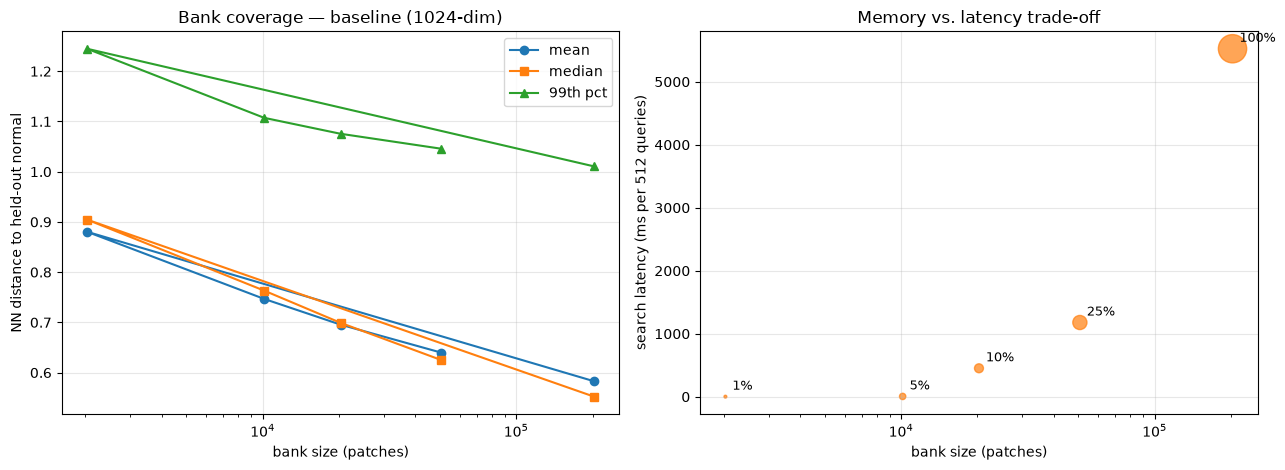

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: coverage vs bank size
ax[0].plot(cov_df["n_patches"], cov_df["nn_mean"], marker="o", label="mean")
ax[0].plot(cov_df["n_patches"], cov_df["nn_p50"],  marker="s", label="median")
ax[0].plot(cov_df["n_patches"], cov_df["nn_p99"],  marker="^", label="99th pct")
ax[0].set_xscale("log")
ax[0].set_xlabel("bank size (patches)")
ax[0].set_ylabel("NN distance to held-out normal")
ax[0].set_title(f"Bank coverage — {EMBED_MODE} ({EMBED_DIM}-dim)")
ax[0].legend(); ax[0].grid(alpha=0.3)

# Right: memory vs latency
ax[1].scatter(lat_df["n_patches"], lat_df["nn_ms_per_512_query"],
              s=cov_df["size_mb"] * 0.5, c="tab:orange", alpha=0.7)
for _, row in lat_df.iterrows():
    ax[1].annotate(str(row["bank"]),
                   (row["n_patches"], row["nn_ms_per_512_query"]),
                   xytext=(5, 5), textcoords="offset points", fontsize=9)
ax[1].set_xscale("log")
ax[1].set_xlabel("bank size (patches)")
ax[1].set_ylabel("search latency (ms per 512 queries)")
ax[1].set_title("Memory vs. latency trade-off")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_coreset_analysis_{TAG}.png", dpi=150)
plt.show()

## **Cell 8 — Save Coreset Indices + Metadata**

In [8]:
torch.save(
    {
        "indices":         sel_big.cpu(),
        "n_total_patches": int(N),
        "seed":            SEED,
        "proj_dim":        PROJ_DIM,
        "ratios":          RATIOS,
        "embed_mode":      EMBED_MODE,
        "embed_dim":       EMBED_DIM,
        "image_size":      IMAGE_SIZE,
        "pool_kernel":     POOL_KERNEL,
        "backbone":        "wide_resnet50_2",
        "feature_layers":  ["layer2", "layer3"],
    },
    MODEL_DIR / f"{CATEGORY}_coreset_indices_{TAG}.pt",
)

meta = {
    "category":                 CATEGORY,
    "embed_mode":               EMBED_MODE,
    "embed_dim":                EMBED_DIM,
    "image_size":               IMAGE_SIZE,
    "pool_kernel":              POOL_KERNEL,
    "backbone":                 "wide_resnet50_2",
    "feature_layers":           ["layer2", "layer3"],
    "n_total_patches":          int(N),
    "ratios":                   RATIOS,
    "bank_sizes":               {k: int(v.shape[0]) for k, v in banks.items()},
    "bank_sizes_mb":            {k: round(v.numel() * 4 / 1e6, 1) for k, v in banks.items()},
    "proj_dim":                 PROJ_DIM,
    "seed":                     SEED,
    "greedy_selection_seconds": round(select_seconds, 1),
    "peak_gpu_mb":              round(torch.cuda.max_memory_allocated() / 1e6, 1),
}
with open(REPORT_DIR / f"{CATEGORY}_coreset_meta_{TAG}.json", "w") as f:
    json.dump(meta, f, indent=2)

print(json.dumps(meta, indent=2))
print("\nSaved:")
print("  ", MODEL_DIR / f"{CATEGORY}_coreset_indices_{TAG}.pt")
print("  ", REPORT_DIR / f"{CATEGORY}_coreset_meta_{TAG}.json")

{
  "category": "metal_nut",
  "embed_mode": "baseline",
  "embed_dim": 1024,
  "image_size": 256,
  "pool_kernel": 3,
  "backbone": "wide_resnet50_2",
  "feature_layers": [
    "layer2",
    "layer3"
  ],
  "n_total_patches": 202752,
  "ratios": [
    0.01,
    0.05,
    0.1,
    0.25
  ],
  "bank_sizes": {
    "100%": 202752,
    "1%": 2027,
    "5%": 10137,
    "10%": 20275,
    "25%": 50688
  },
  "bank_sizes_mb": {
    "100%": 830.5,
    "1%": 8.3,
    "5%": 41.5,
    "10%": 83.0,
    "25%": 207.6
  },
  "proj_dim": 128,
  "seed": 42,
  "greedy_selection_seconds": 922.3,
  "peak_gpu_mb": 3039.1
}

Saved:
   c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\models\metal_nut_coreset_indices_baseline1024.pt
   c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\reports\metrics\metal_nut_coreset_meta_baseline1024.json
